### Build a basic chat bot using lang graph

In [1]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

In [2]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]
    

In [3]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [4]:
from langchain_groq import ChatGroq

llm = ChatGroq(model="openai/gpt-oss-20b")

In [5]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000027078B389E0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000027078CC9070>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [6]:
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [7]:
graph_builder=StateGraph(State)

## Adding node
graph_builder.add_node("llmchatbot",chatbot)
## Adding Edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

## compile the graph
graph=graph_builder.compile()

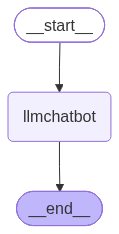

In [8]:
## Visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [9]:
response=graph.invoke({"messages":"Hi"})

In [10]:
response["messages"][-1].content

'Hello! 👋 How can I help you today?'

In [11]:
for event in graph.stream({"messages":"Hi How are you?"}):
    for value in event.values():
           print(value["messages"][-1].content)

Hello! I'm just a bunch of code, so I don't have feelings, but I'm here and ready to help you. How can I assist you today?


In [15]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.ibm.com/think/topics/langgraph',
   'title': 'What is LangGraph? | IBM',
   'content': 'LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. [...] LangGraph illuminates the processes within an AI workflow, allowing full transparency of the agent’s state. Within LangGraph, the “state” feature serves as a memory bank that records and tracks all the valuable information processed by the AI system. It’s similar to a digital notebook where the system captures an

In [16]:
## Custom function
def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [17]:
tools=[tool,multiply]

In [18]:
llm_with_tool=llm.bind_tools(tools)

In [19]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000027078B389E0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000027078CC9070>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for co

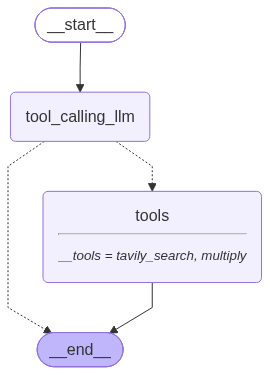

In [20]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [22]:
response=graph.invoke({"messages":"What is the recent ai news"})

In [24]:
response['messages'][-1].content

'{"query": "recent AI news 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-october-2026", "title": "The latest AI news we announced in October 2026", "content": "Put Gemini 4 Argon to work today, and see what’s next for Gemini 4 at the frontier. Following early safety testing, Gemini 4 Argon rolled out globally for complex coding, financial analysis, and legal workflows across Google AI Studio, the Gemini API, Google Cloud, Search, and the Gemini app, while also powering physical-world reasoning through Gemini 4 Argon for Robotics. Showing how quickly we’re pushing the frontier forward, two weeks later we announced Gemini 4 Carbon, our strongest model yet with state-of-the-art cybersecurity and long-horizon capabilities. Just as we did with Argon, we’re taking a deliberate approach to rollout: Carbon is now in pre-release testing with the U.S. government and a subset of trusted 

In [25]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_484dd8b1-102d-4a5b-8307-8fa3a2b2df23)
 Call ID: fc_484dd8b1-102d-4a5b-8307-8fa3a2b2df23
  Args:
    query: recent AI news 2026
    search_depth: advanced
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-october-2026", "title": "The latest AI news we announced in October 2026", "content": "Put Gemini 4 Argon to work today, and see what’s next for Gemini 4 at the frontier. Following early safety testing, Gemini 4 Argon rolled out globally for complex coding, financial analysis, and legal workflows across Google AI Studio, 

In [26]:
response=graph.invoke({"messages":"What is 5 multiplied by 2"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 5 multiplied by 2
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_b69d0c3a-7599-4681-b4e6-bef8d0d62de3)
 Call ID: fc_b69d0c3a-7599-4681-b4e6-bef8d0d62de3
  Args:
    a: 5
    b: 2
================================= Tool Message =================================
Name: multiply

10


In [27]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_25375108-6170-4e13-af0f-1ba46da15a9f)
 Call ID: fc_25375108-6170-4e13-af0f-1ba46da15a9f
  Args:
    query: recent AI news 2026 November
    search_depth: advanced
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026 November", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://arrow-ai.us/blog/ai-news-november-2026", "title": "AI News November 2026: 7 Updates Explained", "content": "Anthropic released Claude Fable 5.2 on November 9\n   API documentation\n   OpenAI–Google Cloud announcement\n   Gemini 4 Argon in the Gemini app\n   donating Agent Skills to the Agentic AI Foundation\n   ChatGPT Images 2.5 announcem

ReAct Agent Architecture

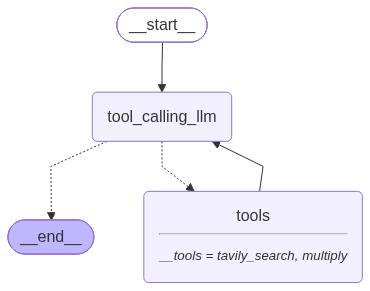

In [28]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [29]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_d735fb3b-89e5-4935-9887-cc8cbc56c2de)
 Call ID: fc_d735fb3b-89e5-4935-9887-cc8cbc56c2de
  Args:
    query: recent AI news
    search_depth: basic
    time_range: week
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=wqNIzUmNt9M", "title": "AI News: This Is The Make or Break Week!!", "content": "Time Stamps:\n00:00 Anthropic Goes Public\n05:33 OpenAI Launches GPT-6.2 Astra and Sol\n10:36 HyperAgent Adds iMessage Support (Sponsor)\n11:34 Google Launches Gemini 4 Neon\n16:35 Astra vs. Sol vs. Neon: Website Test\n21:55 Microsoft Introduces M

Adding Memory In Agentic Graph

In [30]:
response=graph.invoke({"messages":"Hello my name is Raj"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hello my name is Raj
================================== Ai Message ==================================

Hi Raj! 👋 How can I help you today?


In [31]:
response=graph.invoke({"messages":"What is my name"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is my name
================================== Ai Message ==================================

I don’t have that information. If you tell me your name, I’ll remember it for this conversation.


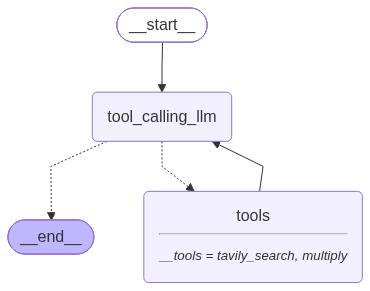

In [40]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [41]:
config={"configurable":{"thread_id":"1"}}

response=graph.invoke({"messages":"Hi my name is Raj"},config=config)

response

{'messages': [HumanMessage(content='Hi my name is Raj', additional_kwargs={}, response_metadata={}, id='463a9385-bade-4903-a388-cb36ab2f23e1'),
  AIMessage(content='Hello Raj! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'We have a conversation: user says "Hi my name is Raj". This is a greeting. We should respond politely, maybe ask how can help. There\'s no need to use tools.'}, response_metadata={'token_usage': {'completion_tokens': 59, 'prompt_tokens': 347, 'total_tokens': 406, 'completion_time': 0.063354611, 'completion_tokens_details': {'reasoning_tokens': 38}, 'prompt_time': 0.018341582, 'prompt_tokens_details': None, 'queue_time': 0.051952946, 'total_time': 0.081696193}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_80501ff3a1', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20e54-881b-725f-aa63-ee09df44d15e-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_

In [42]:
response['messages'][-1].content

'Hello Raj! 👋 How can I help you today?'

In [43]:
response=graph.invoke({"messages":"Hey what is my name"},config=config)

print(response['messages'][-1].content)

Your name is Raj.


In [44]:
response=graph.invoke({"messages":"Hey do you remember mmy name"},config=config)

print(response['messages'][-1].content)

I know you’re Raj, but I don’t keep personal details after our chat ends. Let me know if there’s anything else I can help with!


Streaming

In [45]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

In [46]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

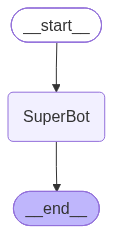

In [47]:
graph=StateGraph(State)

## node
graph.add_node("SuperBot",superbot)
## Edges

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)


graph_builder=graph.compile(checkpointer=memory)


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [48]:
config = {"configurable": {"thread_id": "1"}}

graph_builder.invoke({'messages':"Hi,My name is Raj And I like cricket"},config)

{'messages': [HumanMessage(content='Hi,My name is Raj And I like cricket', additional_kwargs={}, response_metadata={}, id='f97d417b-7302-4a45-82ba-d9a0182844c0'),
  AIMessage(content='Hey Raj! 👋 That’s awesome—cricket’s such a fun sport. Do you have a favorite team or player? Or maybe there’s a particular match that still makes your heart race? I’d love to hear more about what you enjoy most!', additional_kwargs={'reasoning_content': 'User says "Hi, My name is Raj And I like cricket". They haven\'t asked a question. We need to respond in a friendly manner, maybe ask about cricket preferences. Also we must follow policy: no mention of policies. We can respond with a friendly greeting, ask what they like about cricket, maybe ask about favorite teams or players.'}, response_metadata={'token_usage': {'completion_tokens': 131, 'prompt_tokens': 81, 'total_tokens': 212, 'completion_time': 0.135298255, 'completion_tokens_details': {'reasoning_tokens': 70}, 'prompt_time': 0.003843832, 'prompt_t

Streaming
Methods: .stream() and astream()

These methods are sync and async methods for streaming back results.

Additional parameters in streaming modes for graph state

values : This streams the full state of the graph after each node is called.

updates : This streams updates to the state of the graph after each node is called.

In [49]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Raj And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hi Raj! 👋🏼\n\nNice to meet you! Cricket’s a fascinating sport. Do you have a favorite team or player? Or maybe you play it yourself? I’d love to hear more about what you enjoy most—whether it’s the fast‑ball spin, the thrill of a last‑over chase, or the strategy behind the captain’s decisions. Let me know!', additional_kwargs={'reasoning_content': 'We need to respond. The user says "Hi, My name is Raj And I like cricket". The user introduced themselves. We should greet them, ask about cricket. Possibly ask what about cricket? Maybe ask what is their favorite team, etc. Provide friendly conversation.'}, response_metadata={'token_usage': {'completion_tokens': 141, 'prompt_tokens': 81, 'total_tokens': 222, 'completion_time': 0.148590688, 'completion_tokens_details': {'reasoning_tokens': 55}, 'prompt_time': 0.009063679, 'prompt_tokens_details': None, 'queue_time': 0.542846424, 'total_time': 0.157654367}, 'model_name': 'openai/gpt-oss-20b', 'sys

In [50]:

for chunk in graph_builder.stream({'messages':"Hi,My name is Raj And I like cricket"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Raj And I like cricket', additional_kwargs={}, response_metadata={}, id='dfc56d82-4c02-4b11-bc4a-728cd4e189ec'), AIMessage(content='Hi Raj! 👋🏼\n\nNice to meet you! Cricket’s a fascinating sport. Do you have a favorite team or player? Or maybe you play it yourself? I’d love to hear more about what you enjoy most—whether it’s the fast‑ball spin, the thrill of a last‑over chase, or the strategy behind the captain’s decisions. Let me know!', additional_kwargs={'reasoning_content': 'We need to respond. The user says "Hi, My name is Raj And I like cricket". The user introduced themselves. We should greet them, ask about cricket. Possibly ask what about cricket? Maybe ask what is their favorite team, etc. Provide friendly conversation.'}, response_metadata={'token_usage': {'completion_tokens': 141, 'prompt_tokens': 81, 'total_tokens': 222, 'completion_time': 0.148590688, 'completion_tokens_details': {'reasoning_tokens': 55}, 'prompt_time': 0.0

In [51]:
# Create a thread
config = {"configurable": {"thread_id": "4"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Raj And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hi Raj! It’s great to meet a cricket fan. Which team do you follow, or do you prefer the international leagues? Also, are you into batting, bowling, or just watching the matches?', additional_kwargs={'reasoning_content': 'User says: "Hi,My name is Raj And I like cricket". We need to respond in a friendly manner, maybe ask about cricket or what about it. The user wants a response. Let\'s respond.'}, response_metadata={'token_usage': {'completion_tokens': 93, 'prompt_tokens': 81, 'total_tokens': 174, 'completion_time': 0.098610816, 'completion_tokens_details': {'reasoning_tokens': 43}, 'prompt_time': 0.003963433, 'prompt_tokens_details': None, 'queue_time': 0.049241215, 'total_time': 0.102574249}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_c5a89987dc', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20e62-f555-7427-aadb-4d7f5ae5c2a5-0', tool_calls=[], invalid

In [52]:
for chunk in graph_builder.stream({'messages':"I also like football"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Raj And I like cricket', additional_kwargs={}, response_metadata={}, id='6f829828-d5c9-4f97-bb68-a851c9fe814c'), AIMessage(content='Hi Raj! It’s great to meet a cricket fan. Which team do you follow, or do you prefer the international leagues? Also, are you into batting, bowling, or just watching the matches?', additional_kwargs={'reasoning_content': 'User says: "Hi,My name is Raj And I like cricket". We need to respond in a friendly manner, maybe ask about cricket or what about it. The user wants a response. Let\'s respond.'}, response_metadata={'token_usage': {'completion_tokens': 93, 'prompt_tokens': 81, 'total_tokens': 174, 'completion_time': 0.098610816, 'completion_tokens_details': {'reasoning_tokens': 43}, 'prompt_time': 0.003963433, 'prompt_tokens_details': None, 'queue_time': 0.049241215, 'total_time': 0.102574249}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_c5a89987dc', 'service_tier': 'on_demand', 'finish_r